In [11]:
!unzip -o archive.zip

Archive:  archive.zip
  inflating: SampleSuperstore.csv    


In [12]:
import pandas as pd

raw = pd.read_csv("SampleSuperstore.csv")
print("Rows before:", len(raw), "| Duplicates:", raw.duplicated().sum())

df = raw.drop_duplicates().copy()
print("Rows after:", len(df))

df.to_csv("superstore_cleaned.csv", index=False)

Rows before: 9994 | Duplicates: 17
Rows after: 9977


In [13]:
df["Profit Margin"] = df["Profit"] / df["Sales"]
df.groupby("Category")[["Sales", "Profit"]].sum()

,Sales,Profit
Category,,
Furniture,741306.3133,18421.8137
Office Supplies,718735.2440,122364.6608
Technology,836154.0330,145454.9481


In [14]:
furniture = df[df["Category"] == "Furniture"]

furniture.groupby("Sub-Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    AvgDiscount=("Discount", "mean")
).round(2)

,Sales,Profit,AvgDiscount
Sub-Category,,,
Bookcases,114880.00,-3472.56,0.21
Chairs,327777.76,26567.13,0.17
Furnishings,91683.02,13052.72,0.14
Tables,206965.53,-17725.48,0.26


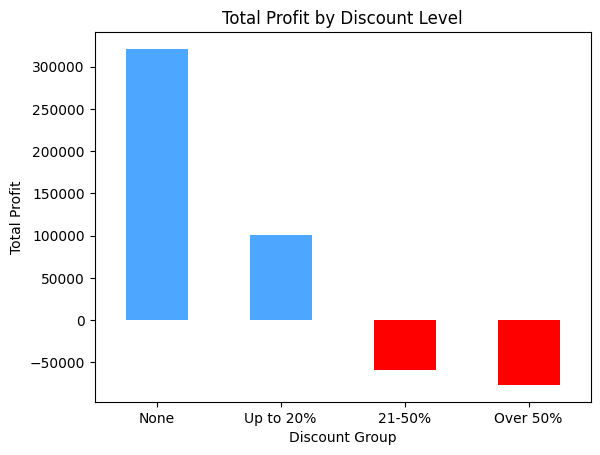

In [15]:
import matplotlib.pyplot as plt

df["Discount Group"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.2, 0.5, 1],
    labels=["None", "Up to 20%", "21-50%", "Over 50%"]
)

profit_by_discount = df.groupby("Discount Group", observed=True)["Profit"].sum()

profit_by_discount.plot(kind="bar", color=["#4da6ff", "#4da6ff", "red", "red"])
plt.title("Total Profit by Discount Level")
plt.xlabel("Discount Group")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.savefig("discount_vs_profit.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
from scipy import stats

high = df[df["Discount"] > 0.2]["Profit"]
low = df[df["Discount"] <= 0.2]["Profit"]

print("High discount orders:", len(high), "| average profit:", round(high.mean(), 2))
print("Low discount orders:", len(low), "| average profit:", round(low.mean(), 2))

t_stat, p_value = stats.ttest_ind(high, low, equal_var=False)
print("t-statistic:", round(t_stat, 2))
print("p-value:", p_value)

High discount orders: 1391 | average profit: -97.31
Low discount orders: 8586 | average profit: 49.1
t-statistic: -16.14
p-value: 2.372075977545879e-54


In [17]:
import statsmodels.api as sm

X = sm.add_constant(df[["Discount", "Sales", "Quantity"]])
model = sm.OLS(df["Profit"], X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.273
Model:                            OLS   Adj. R-squared:                  0.273
Method:                 Least Squares   F-statistic:                     1247.
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        06:59:56   Log-Likelihood:                -67015.
No. Observations:                9977   AIC:                         1.340e+05
Df Residuals:                    9973   BIC:                         1.341e+05
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         35.0216      4.224      8.291      0.0